# Estimar emisiones con sensores que se mueven juntos
### Unidades 2, 3 y 4 · Laboratorio de Datos I · UNTDF

**Parcial I1 · Ingeniería Industrial · Resolución individual domiciliaria · Plazo: dos semanas**

Una turbina de gas registra condiciones ambientales y de operación. Se estudiará la relación entre esos sensores y las emisiones de óxidos de nitrógeno para comparar regresión lineal y Ridge.

**Pregunta central:** ¿Ridge aporta precisión o menor variación de coeficientes frente a una regresión lineal con sensores correlacionados, dentro de la población histórica de 2011–2013?

Nombre y apellido: Candelaria Carro· Carrera: Ingenieria Industrial · Fecha de entrega: 12/10/2026


## Guía de trabajo

- Resolver diez consignas C1–C10, conservando los títulos y agregando celdas cuando sea necesario.
- Usar los archivos locales, diccionario y particiones provistos. No se requiere termodinámica avanzada ni obtener datos de otra planta.
- La cátedra entrega setup, carga y una ayuda para el diagnóstico de coeficientes. El EDA, los modelos y la interpretación se resuelven en los espacios indicados.
- Comparar una referencia media, lineal y cuatro Ridge fijados. El diagnóstico de estabilidad usa cinco submuestras de entrenamiento; no es una búsqueda adicional.
- Explorar sólo entrenamiento. Usar validación fija en C6 para comparar y C7 para seleccionar. Abrir prueba recién en C8; conservar los modelos entrenados, sin reajustarlos con validación.
- Entregar el notebook ejecutado desde kernel limpio, con respuestas, salidas y la carpeta `datasets/`. No se pide informe separado.

La ejecución del esqueleto vacío comprueba el soporte, no resuelve el parcial. Las etiquetas de prueba están incluidas; el orden de acceso es parte del método. La celda siguiente configura el entorno.

In [13]:
# Si hiciera falta, instalar previamente las dependencias de requirements.txt.
# === Setup de la cátedra — Laboratorio de Datos I (UNTDF) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from importlib.metadata import version
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

SEED = 42
rng = np.random.default_rng(SEED)

# Paleta de la cátedra (fondo claro) — usar por semántica, no por gusto
AZUL   = "#4A7A9B"  # serie base
CIAN   = "#5AA9D6"  # serie secundaria / estructura
DORADO = "#D8A24A"  # transición
AMBAR  = "#E89340"  # único acento: lo que sostiene la conclusión
GRIS   = "#B9C4CE"  # contexto / referencia
TINTA  = "#0E1620"  # texto, ejes y bordes
PROGRESION = [AZUL, CIAN, DORADO, AMBAR]

plt.rcParams.update({
    "figure.figsize": (11.5, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRIS, "grid.alpha": 0.35,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": TINTA, "axes.labelcolor": TINTA, "axes.edgecolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[AZUL, AMBAR, CIAN, DORADO, GRIS]),
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

**Interpretación.** El entorno y la paleta quedan disponibles. Todas las importaciones se concentran arriba; las versiones probadas se indican en `requirements.txt`.

# 1. Comprender la medición sin diseñar una planta
## 1.1 Contexto y vocabulario

En una turbina de gas se comprime aire, se combina con combustible y los gases calientes se expanden en una turbina que impulsa generación de energía. Las condiciones ambientales y operativas varían juntas: por ejemplo, modificar la carga puede acompañarse de cambios en temperaturas y presiones. Por eso distintos sensores pueden aportar información parcialmente redundante.

El objetivo `NOX` representa la concentración de óxidos de nitrógeno, en **mg/m³**. No es la masa total emitida por hora. Una fila reúne mediciones agregadas durante una hora, por promedio o suma según la variable. Se usarán nueve mediciones contemporáneas para estimar NOX del mismo registro: es una estimación dentro de la población histórica, **no un pronóstico de la hora siguiente**.

La fuente UCI reúne una planta de Turquía entre 2011 y 2015; el núcleo del examen usa sólo 2011–2013. Se conoce el orden cronológico de las filas originales, pero no sus fechas exactas. No construir timestamps ni asumir que todos los registros son horas consecutivas sin interrupciones.

Lecturas seleccionadas, de 3–4 horas como máximo: [ficha UCI y variables](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set) y [tres secciones de una turbina de gas, Department of Energy](https://www.energy.gov/hgeo/how-gas-turbine-power-plants-work), limitada a compresor, combustión y turbina. El glosario y el esquema provistos permiten trabajar sin cálculos termodinámicos.

## 1.2 Esquema conceptual del proceso

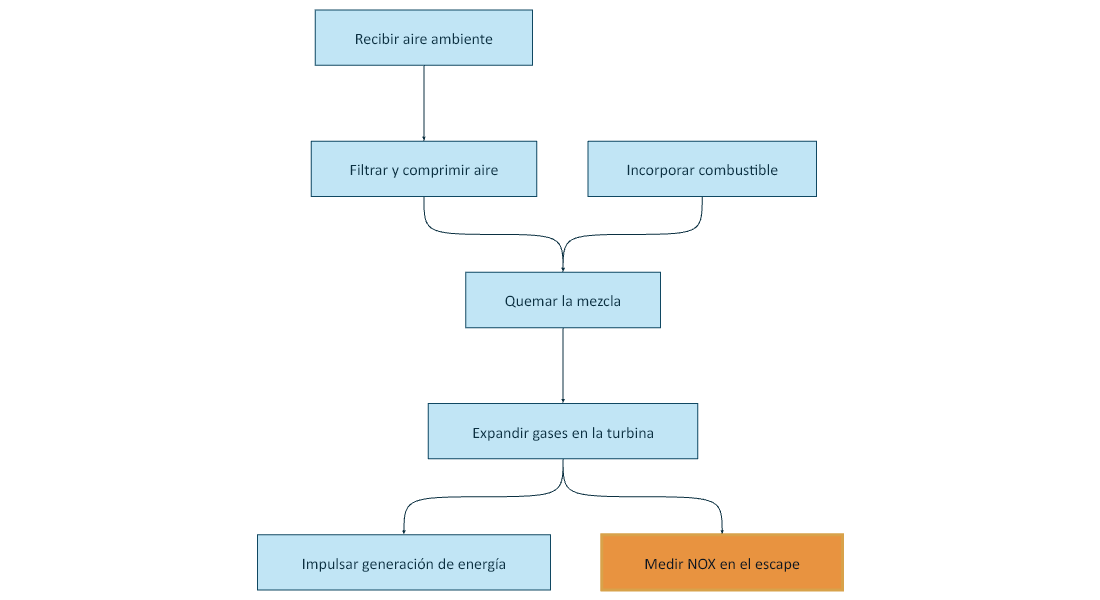

Esquema simplificado adaptado de la explicación del Department of Energy. Omite mecanismos auxiliares y no ubica físicamente cada sensor de esta planta; sirve para distinguir entradas ambientales, operación y emisiones. El par Mermaid y PNG está en `recursos/`.

## 1.3 Diccionario de sensores

| Columna | Significado | Unidad publicada | Uso |
|---|---|---|---|
| `AT` | Temperatura ambiente | °C | Predictor |
| `AP` | Presión ambiente | mbar | Predictor |
| `AH` | Humedad ambiente | % | Predictor |
| `AFDP` | Diferencia de presión del filtro de aire | mbar | Predictor |
| `GTEP` | Presión de escape de la turbina | mbar | Predictor |
| `TIT` | Temperatura de entrada de la turbina | °C | Predictor |
| `TAT` | Temperatura posterior a la turbina | °C | Predictor |
| `TEY` | Producción energética de la turbina | MWh | Predictor |
| `CDP` | Presión de descarga del compresor | mbar, según UCI | Predictor |
| `NOX` | Óxidos de nitrógeno | mg/m³ | Objetivo |
| `anio` | Archivo anual de origen | Año | Auxiliar para EDA y diagnóstico; excluido de X |
| `id_medicion` | Año y posición original | Identificador | Sólo trazabilidad; excluido de X |

La unidad de `CDP` se conserva tal como está publicada, sin reinterpretar sus valores ni convertirlos por plausibilidad física. La ficha muestra valores de humedad ligeramente superiores al 100 %: registrarlos y discutirlos, sin corregirlos automáticamente. `CO` no se distribuye como predictor; se excluye para concentrar el problema en ambiente y operación, no en otra emisión simultánea.

## 1.4 Consigna C1 — Formular la estimación

Completar una tabla con unidad de observación, objetivo y unidad, predictores admisibles, momento de disponibilidad y alcance de la estimación. Distinguir concentración de masa total emitida y estimación contemporánea de pronóstico. Explicar por qué no se puede emitir una conclusión normativa sobre contaminación a partir de este parcial.

**Respuesta.**

| Elemento | Formulación |
|---|---|
| **Unidad de observación** | Una fila = un registro horario de una turbina de gas, con variables agregadas durante esa hora (media o suma según la variable), identificado por `id_medicion`. |
| **Objetivo y unidad** | `NOX`, concentración de óxidos de nitrógeno, en **mg/m³**. |
| **Predictores admisibles** | Los nueve: `AT` (°C), `AP` (mbar), `AH` (%), `AFDP` (mbar), `GTEP` (mbar), `TIT` (°C), `TAT` (°C), `TEY` (MWh) y `CDP` (mbar, según UCI). |
| **Momento de disponibilidad** | Se miden en la misma hora del mismo registro que `NOX`, es decir, de forma contemporánea (mismo intervalo $t$). |
| **Alcance de la estimación** | Población histórica de una turbina en Turquía, años 2011–2013, $N = 22.191$ registros, con partición aleatoria fija. |

**Diferenciaciones clave**

- **Concentración vs. masa total.** `NOX` es una concentración ($mg/m^3$), no la masa total emitida ($kg/h$). Para obtener la masa habría que multiplicar por el caudal volumétrico de gases de escape, que no está en el paquete.
- **Estimación contemporánea vs. pronóstico.** Se estima el `NOX` de una hora con los sensores de esa misma hora ($t$); no se pronostica $t+1$. Además, las filas tienen orden cronológico pero no fechas ni garantía de horas consecutivas.

**Por qué no hay conclusión normativa**

- El paquete no incluye límites legales ni protocolos de cumplimiento (ni el caudal ni, típicamente, la corrección por $O_2$ de referencia que se exige).
- Los datos son de una sola planta y de 2011–2013, sin validez para otras plantas o períodos.
- Los modelos capturan asociaciones predictivas, no causas ni conformidad reglamentaria.

<!-- 
| Elemento | Formulación |
|---|---|
| **Unidad de observación** | Una fila = un registro horario de una turbina de gas, con variables agregadas durante esa hora (media o suma según la variable), identificado por `id_medicion`. |
| **Objetivo y unidad** | `NOX`, concentración de óxidos de nitrógeno, en **mg/m³**. |
| **Predictores admisibles** | Los nueve: `AT` (°C), `AP` (mbar), `AH` (%), `AFDP` (mbar), `GTEP` (mbar), `TIT` (°C), `TAT` (°C), `TEY` (MWh) y `CDP` (mbar, según UCI). |
| **Momento de disponibilidad** | Se miden en la misma hora del mismo registro que `NOX`, es decir, de forma contemporánea (mismo intervalo $t$). |
| **Alcance de la estimación** | Población histórica de una turbina en Turquía, años 2011–2013, $N = 22.191$ registros, con partición aleatoria fija. | -->

# 2. Distinguir población histórica de período futuro
## 2.1 Contrato de separación

El núcleo contiene **22.191 registros**: 7.411 de 2011, 7.628 de 2012 y 7.152 de 2013. La cátedra realiza una partición aleatoria fija aproximada 70/15/15, semilla 42. No se elimina ninguna fila para ajustar tamaños.

| Bloques | Datos | Finalidad |
|---|---|---|
| C3–C5 | Entrenamiento | Auditar, explorar y preparar |
| C6 | Entrenamiento y validación fija | Comparar modelos |
| C7 | Validación; submuestras sólo de entrenamiento | Seleccionar por RMSE y diagnosticar coeficientes |
| C8–C9 | Prueba reservada | Evaluar una vez y analizar errores |

Este caso usa validación fija, **sin validación cruzada**. Al mezclar períodos, la prueba puede contener observaciones próximas a otras usadas para ajustar: la dependencia temporal puede hacer la evaluación más favorable que un despliegue futuro.

UCI recomienda, para comparar con el artículo original, desarrollo 2011–2013 y prueba 2014–2015. **Nuestro protocolo pedagógico es distinto** y no sirve para afirmar que se replica ese benchmark. Los años 2014–2015 quedan fuera del examen y sólo podrían usarse en una extensión futura acordada.

## 2.2 Cargar entrenamiento y validación

El soporte abre sólo esas tablas y controla identificadores disjuntos. No resume ni carga prueba todavía. La auditoría de C3 es una tarea adicional.

In [14]:
RUTA_DATOS=Path("datasets")
PREDICTORES=["AT","AP","AH","AFDP","GTEP","TIT","TAT","TEY","CDP"]
OBJETIVO="NOX"
PROHIBIDAS=["id_medicion","anio","CO",OBJETIVO]
entrenamiento=pd.read_csv(RUTA_DATOS/"entrenamiento.csv")
validacion=pd.read_csv(RUTA_DATOS/"validacion.csv")
assert set(entrenamiento.id_medicion).isdisjoint(set(validacion.id_medicion))
display(pd.DataFrame({"conjunto":["entrenamiento","validacion"],"registros":[len(entrenamiento),len(validacion)]}))

,conjunto,registros
0,entrenamiento,15533
1,validacion,3329


**Interpretación.** Las dos tablas están disponibles. El control de IDs evita filas compartidas, pero no elimina la dependencia temporal ni demuestra que los registros sean independientes.

## 2.3 Consigna C2 — Justificar información y límites

Explicar por qué se excluyen año, ID, CO y objetivo. Aclarar que excluir CO es una delimitación del problema, no la prueba de que toda medición simultánea constituya fuga. Comparar qué pregunta responde la partición aleatoria con la que respondería una reserva de años posteriores. No modificar el protocolo entregado.

**Por qué se excluyen estas columnas**

- **`NOX`:** es el objetivo. Si entrara en X, el modelo tendría la respuesta como dato de entrada.
- **`id_medicion`:** es solo trazabilidad (año y posición original). No es una medición del proceso ni un timestamp.
- **`anio`:** es una variable auxiliar para el EDA y el diagnóstico. Sirve para describir y comparar por año, no para estimar `NOX`.
- **`CO`:** es otra emisión medida simultáneamente. Se excluye para concentrar el problema en ambiente y operación. Es una **delimitación del problema**, no la prueba de que toda medición simultánea constituya fuga: los nueve predictores también se miden en la misma hora que `NOX`.

**Partición aleatoria vs. reserva de años posteriores**

- **Partición aleatoria (la del parcial):** responde si, dentro de la población histórica 2011–2013, se puede estimar `NOX` en registros parecidos a los usados para ajustar. Puede haber dependencia temporal entre conjuntos, por lo que la evaluación puede resultar más favorable que en un uso futuro.
- **Reserva de años posteriores (por ejemplo, 2014–2015):** respondería si el modelo sigue funcionando en un período futuro, con posibles cambios de condiciones.

El protocolo entregado no se modifica y no permite afirmar que se replica el benchmark de UCI.

# 3. Auditar mediciones y unidades
## 3.1 Consigna C3 — Registrar controles de calidad

Usando sólo entrenamiento, presentar tipos y nulos, duplicados de ID y de mediciones, rangos de los nueve predictores y NOX, conteos por año y cantidad de valores de humedad fuera del intervalo 0–100. Identificar sensores con escalas muy distintas. Registrar hallazgo, cantidad y decisión; conservar todas las filas conforme al contrato y no convertir unidades ni inventar fechas. Ausencia de nulos es un resultado válido.

In [15]:

# Espacio de resolución — C3 · auditoría (solo entrenamiento)
cols = PREDICTORES + [OBJETIVO]

print("=== 1. TIPOS DE DATOS Y NULOS ===")
entrenamiento.info()
print("\nNulos por columna:")
print(entrenamiento.isnull().sum())

print("\n=== 2. DUPLICADOS ===")
dup_id = int(entrenamiento["id_medicion"].duplicated().sum())
dup_med = int(entrenamiento.duplicated(subset=cols).sum())
print(f"Duplicados por ID: {dup_id}")
print(f"Duplicados por mediciones (9 predictores + NOX): {dup_med}")

print("\n=== 3. RANGOS Y ESCALAS ===")
rangos = entrenamiento[cols].describe().T[["min", "mean", "max", "std"]]
rangos["amplitud"] = rangos["max"] - rangos["min"]
display(rangos)

print("\n=== 4. CONTEOS POR AÑO ===")
print(entrenamiento["anio"].value_counts().sort_index())

print("\n=== 5. HUMEDAD (AH) FUERA DE 0–100 ===")
ah_fuera = int(((entrenamiento["AH"] < 0) | (entrenamiento["AH"] > 100)).sum())
print(f"Registros con AH fuera de [0, 100]: {ah_fuera}")

print("\n=== 6. REGISTRO DE HALLAZGOS ===")
display(pd.DataFrame({
    "hallazgo": ["Valores nulos", "IDs duplicados", "Mediciones duplicadas", "Humedad fuera de 0–100"],
    "cantidad": [int(entrenamiento[cols].isna().sum().sum()), dup_id, dup_med, ah_fuera],
    "decision": [
        "Sin imputación; se conservan todas las filas.",
        "Se conservan todas las filas.",
        "Se conservan todas las filas.",
        "Se registra y se conserva, sin corregir."
    ]
}))# Espacio de resolución — C3 · auditoría (solo entrenamiento)
cols = PREDICTORES + [OBJETIVO]

print("=== 1. TIPOS DE DATOS Y NULOS ===")
entrenamiento.info()
print("\nNulos por columna:")
print(entrenamiento.isnull().sum())

print("\n=== 2. DUPLICADOS ===")
dup_id = int(entrenamiento["id_medicion"].duplicated().sum())
dup_med = int(entrenamiento.duplicated(subset=cols).sum())
print(f"Duplicados por ID: {dup_id}")
print(f"Duplicados por mediciones (9 predictores + NOX): {dup_med}")

print("\n=== 3. RANGOS Y ESCALAS ===")
rangos = entrenamiento[cols].describe().T[["min", "mean", "max", "std"]]
rangos["amplitud"] = rangos["max"] - rangos["min"]
display(rangos)

print("\n=== 4. CONTEOS POR AÑO ===")
print(entrenamiento["anio"].value_counts().sort_index())

print("\n=== 5. HUMEDAD (AH) FUERA DE 0–100 ===")
ah_fuera = int(((entrenamiento["AH"] < 0) | (entrenamiento["AH"] > 100)).sum())
print(f"Registros con AH fuera de [0, 100]: {ah_fuera}")

print("\n=== 6. REGISTRO DE HALLAZGOS ===")
display(pd.DataFrame({
    "hallazgo": ["Valores nulos", "IDs duplicados", "Mediciones duplicadas", "Humedad fuera de 0–100", "Escalas muy distintas (TIT, TEY vs. AFDP, CDP)"],
    "cantidad": [int(entrenamiento[cols].isna().sum().sum()), dup_id, dup_med, ah_fuera, 4],
    "decision": [
        "Sin imputación; se conservan todas las filas.",
        "Se conservan todas las filas.",
        "Se conservan todas las filas.",
        "Se registra y se conserva, sin corregir.",
        "Se estandariza dentro del pipeline (C5)."
    ]
}))


=== 1. TIPOS DE DATOS Y NULOS ===
<class 'pandas.DataFrame'>
RangeIndex: 15533 entries, 0 to 15532
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_medicion  15533 non-null  str    
 1   anio         15533 non-null  int64  
 2   AT           15533 non-null  float64
 3   AP           15533 non-null  float64
 4   AH           15533 non-null  float64
 5   AFDP         15533 non-null  float64
 6   GTEP         15533 non-null  float64
 7   TIT          15533 non-null  float64
 8   TAT          15533 non-null  float64
 9   TEY          15533 non-null  float64
 10  CDP          15533 non-null  float64
 11  NOX          15533 non-null  float64
dtypes: float64(10), int64(1), str(1)
memory usage: 1.4 MB

Nulos por columna:
id_medicion    0
anio           0
AT             0
AP             0
AH             0
AFDP           0
GTEP           0
TIT            0
TAT            0
TEY            0
CDP            0
NOX           

,min,mean,max,std,amplitud
AT,0.28985,17.738379,34.8310,7.380709,34.54115
AP,985.85000,1012.829990,1034.2000,6.383340,48.35000
AH,27.50400,79.566031,100.2000,13.950929,72.69600
AFDP,2.09920,4.038765,7.5549,0.808415,5.45570
GTEP,17.91200,25.334553,37.1890,4.228293,19.27700
TIT,1000.80000,1083.173991,1100.8000,16.764135,100.00000
TAT,512.45000,545.524009,550.6100,7.714126,38.16000
TEY,100.32000,133.593689,174.6100,15.987569,74.29000
CDP,9.87540,12.064528,15.0810,1.112038,5.20560
NOX,27.76500,68.764151,119.9100,11.083133,92.14500



=== 4. CONTEOS POR AÑO ===
anio
2011    5207
2012    5306
2013    5020
Name: count, dtype: int64

=== 5. HUMEDAD (AH) FUERA DE 0–100 ===
Registros con AH fuera de [0, 100]: 266

=== 6. REGISTRO DE HALLAZGOS ===


,hallazgo,cantidad,decision
0,Valores nulos,0,Sin imputación; se conservan todas las filas.
1,IDs duplicados,0,Se conservan todas las filas.
2,Mediciones duplicadas,0,Se conservan todas las filas.
3,Humedad fuera de 0–100,266,"Se registra y se conserva, sin corregir."


=== 1. TIPOS DE DATOS Y NULOS ===
<class 'pandas.DataFrame'>
RangeIndex: 15533 entries, 0 to 15532
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_medicion  15533 non-null  str    
 1   anio         15533 non-null  int64  
 2   AT           15533 non-null  float64
 3   AP           15533 non-null  float64
 4   AH           15533 non-null  float64
 5   AFDP         15533 non-null  float64
 6   GTEP         15533 non-null  float64
 7   TIT          15533 non-null  float64
 8   TAT          15533 non-null  float64
 9   TEY          15533 non-null  float64
 10  CDP          15533 non-null  float64
 11  NOX          15533 non-null  float64
dtypes: float64(10), int64(1), str(1)
memory usage: 1.4 MB

Nulos por columna:
id_medicion    0
anio           0
AT             0
AP             0
AH             0
AFDP           0
GTEP           0
TIT            0
TAT            0
TEY            0
CDP            0
NOX           

,min,mean,max,std,amplitud
AT,0.28985,17.738379,34.8310,7.380709,34.54115
AP,985.85000,1012.829990,1034.2000,6.383340,48.35000
AH,27.50400,79.566031,100.2000,13.950929,72.69600
AFDP,2.09920,4.038765,7.5549,0.808415,5.45570
GTEP,17.91200,25.334553,37.1890,4.228293,19.27700
TIT,1000.80000,1083.173991,1100.8000,16.764135,100.00000
TAT,512.45000,545.524009,550.6100,7.714126,38.16000
TEY,100.32000,133.593689,174.6100,15.987569,74.29000
CDP,9.87540,12.064528,15.0810,1.112038,5.20560
NOX,27.76500,68.764151,119.9100,11.083133,92.14500



=== 4. CONTEOS POR AÑO ===
anio
2011    5207
2012    5306
2013    5020
Name: count, dtype: int64

=== 5. HUMEDAD (AH) FUERA DE 0–100 ===
Registros con AH fuera de [0, 100]: 266

=== 6. REGISTRO DE HALLAZGOS ===


,hallazgo,cantidad,decision
0,Valores nulos,0,Sin imputación; se conservan todas las filas.
1,IDs duplicados,0,Se conservan todas las filas.
2,Mediciones duplicadas,0,Se conservan todas las filas.
3,Humedad fuera de 0–100,266,"Se registra y se conserva, sin corregir."
4,"Escalas muy distintas (TIT, TEY vs. AFDP, CDP)",4,Se estandariza dentro del pipeline (C5).


**Interpretación.** El conjunto de entrenamiento tiene 15.533 registros y no presenta valores nulos ni datos duplicados, por lo que no fue necesario eliminar ni completar datos. Se encontraron 266 registros de humedad `AH` por encima del 100 %, pero se conservaron porque corresponden a los datos originales. También se observa que los sensores tienen escalas muy diferentes, por lo que es necesario estandarizarlos antes de ajustar los modelos.

# 4. Examinar emisiones y sensores redundantes
## 4.1 Consigna C4 — Tres figuras y una tabla

Producir en entrenamiento: (1) histograma de NOX con media señalada; (2) matriz de correlaciones de Pearson entre los nueve predictores; (3) dispersión del par con mayor correlación absoluta fuera de la diagonal, identificando ambos sensores y sus unidades. Señalar cómo esa asociación puede afectar la interpretación de coeficientes.

Agregar una tabla por año con cantidad de registros, media y desvío de NOX. Justificar dos decisiones de preparación o modelado. No interpretar la correlación como causalidad ni usar los gráficos para eliminar predictores: el menú mantiene los nueve.

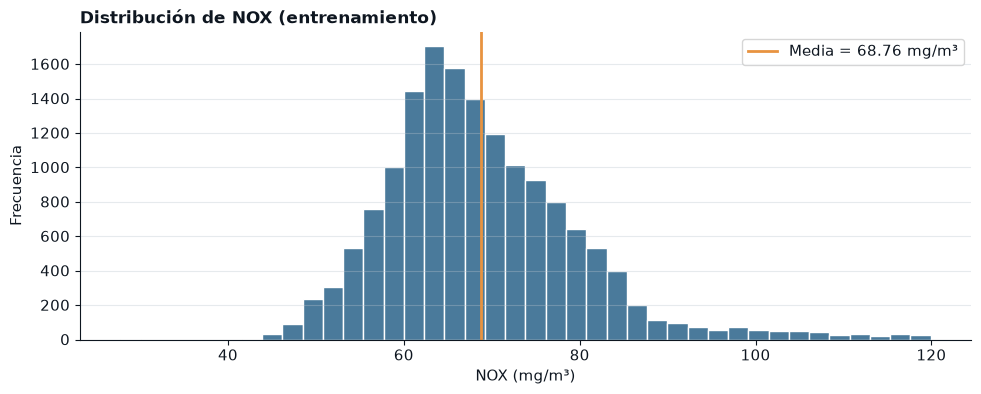

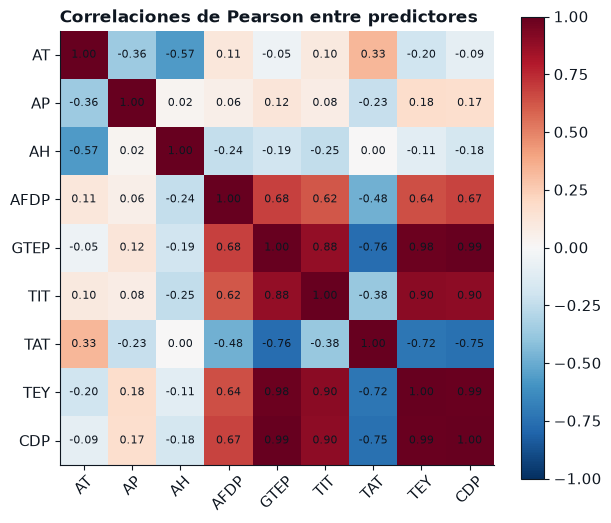

Par con mayor |correlación|: GTEP y CDP (r = 0.994)


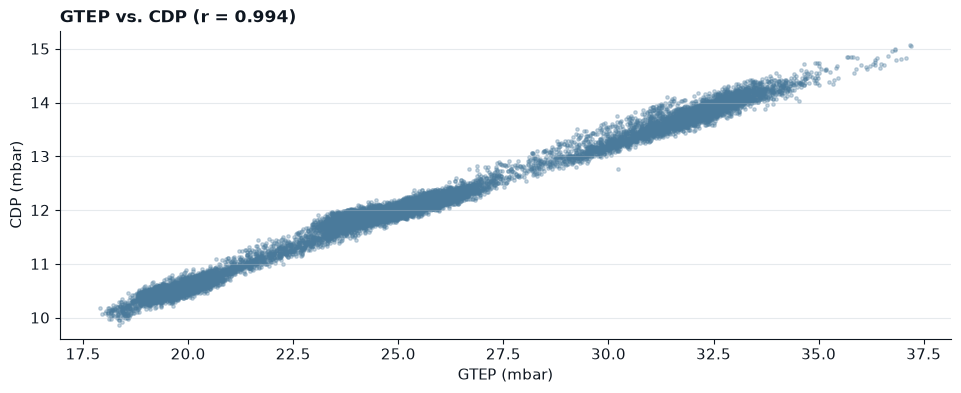

,registros,media_NOX,desvio_NOX
anio,,,
2011,5207,67.586,10.694
2012,5306,68.722,10.160
2013,5020,70.031,12.222


In [16]:
# Espacio de resolución — C4 · EDA (solo entrenamiento)
unidades = {"AT": "°C", "AP": "mbar", "AH": "%", "AFDP": "mbar", "GTEP": "mbar",
            "TIT": "°C", "TAT": "°C", "TEY": "MWh", "CDP": "mbar"}

# (1) Histograma de NOX con la media señalada
media_nox = entrenamiento[OBJETIVO].mean()
fig, ax = plt.subplots()
ax.hist(entrenamiento[OBJETIVO], bins=40, color=AZUL, edgecolor="white")
ax.axvline(media_nox, color=AMBAR, linewidth=2, label=f"Media = {media_nox:.2f} mg/m³")
ax.set_title("Distribución de NOX (entrenamiento)")
ax.set_xlabel("NOX (mg/m³)")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.show()

# (2) Matriz de correlaciones de Pearson entre los nueve predictores
corr = entrenamiento[PREDICTORES].corr(method="pearson")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(PREDICTORES)))
ax.set_xticklabels(PREDICTORES, rotation=45)
ax.set_yticks(range(len(PREDICTORES)))
ax.set_yticklabels(PREDICTORES)
for i in range(len(PREDICTORES)):
    for j in range(len(PREDICTORES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Correlaciones de Pearson entre predictores")
fig.colorbar(im)
plt.show()

# (3) Dispersión del par con mayor correlación absoluta fuera de la diagonal
abs_corr = corr.abs().where(~np.eye(len(PREDICTORES), dtype=bool))
sensor1, sensor2 = abs_corr.stack().idxmax()
r = corr.loc[sensor1, sensor2]
print(f"Par con mayor |correlación|: {sensor1} y {sensor2} (r = {r:.3f})")

fig, ax = plt.subplots()
ax.scatter(entrenamiento[sensor1], entrenamiento[sensor2], s=6, alpha=0.3, color=AZUL)
ax.set_title(f"{sensor1} vs. {sensor2} (r = {r:.3f})")
ax.set_xlabel(f"{sensor1} ({unidades[sensor1]})")
ax.set_ylabel(f"{sensor2} ({unidades[sensor2]})")
plt.show()

# Tabla por año: registros, media y desvío de NOX
tabla_anio = entrenamiento.groupby("anio")[OBJETIVO].agg(
    registros="count", media_NOX="mean", desvio_NOX="std").round(3)
display(tabla_anio)

**Interpretación.** `NOX` presenta una media de 68,76 mg/m³ y algunos valores altos que llegan aproximadamente a 120 mg/m³. Se observa una correlación muy alta entre varios sensores, especialmente entre `GTEP` y `CDP` (r = 0,994), lo que indica que se comportan de manera similar y aportan información redundante. También se observan algunas diferencias en los valores de `NOX` entre los años, aunque no son muy grandes. Por las diferentes escalas de los sensores y la alta correlación entre ellos, se decidió mantener los nueve predictores y estandarizarlos antes de ajustar los modelos.


# 5. Preparar y definir un diagnóstico de coeficientes
## 5.1 Consigna C5 — Construir entradas y explicar el escalado

Crear `X_ent`, `y_ent`, `X_val`, `y_val` con las nueve columnas autorizadas. Verificar exclusiones. Documentar en una tabla los rangos originales, tratamiento y motivo. Usar `StandardScaler` dentro de cada pipeline, tanto para lineal como Ridge, ajustado sólo con entrenamiento. No eliminar sensores, generar polinomios, imputar si no hay nulos ni recortar extremos. Explicar por qué no se deben comparar directamente coeficientes expresados en unidades originales distintas.

In [17]:
# Espacio de resolución — C5 · preparación
unidades = {"AT": "°C", "AP": "mbar", "AH": "%", "AFDP": "mbar", "GTEP": "mbar",
            "TIT": "°C", "TAT": "°C", "TEY": "MWh", "CDP": "mbar (según UCI)"}

# Entradas y objetivo, con las nueve columnas autorizadas
X_ent, y_ent = entrenamiento[PREDICTORES], entrenamiento[OBJETIVO]
X_val, y_val = validacion[PREDICTORES], validacion[OBJETIVO]

# Verificación de exclusiones
assert list(X_ent.columns) == PREDICTORES and list(X_val.columns) == PREDICTORES
assert set(PROHIBIDAS).isdisjoint(X_ent.columns)
assert set(PROHIBIDAS).isdisjoint(X_val.columns)
print("Exclusiones verificadas: X no contiene", PROHIBIDAS)
print(f"X_ent: {X_ent.shape} | y_ent: {y_ent.shape} | X_val: {X_val.shape} | y_val: {y_val.shape}")

# Tabla: rangos originales, tratamiento y motivo (rangos de entrenamiento)
tabla_prep = pd.DataFrame({
    "unidad": pd.Series(unidades),
    "min": X_ent.min(),
    "max": X_ent.max(),
    "desvio": X_ent.std().round(3),
})
tabla_prep["tratamiento"] = "StandardScaler en el pipeline, ajustado solo con entrenamiento"
tabla_prep["motivo"] = "Escala propia; evita que la unidad domine el ajuste y la penalización de Ridge"
display(tabla_prep)

Exclusiones verificadas: X no contiene ['id_medicion', 'anio', 'CO', 'NOX']
X_ent: (15533, 9) | y_ent: (15533,) | X_val: (3329, 9) | y_val: (3329,)


,unidad,min,max,desvio,tratamiento,motivo
AT,°C,0.28985,34.8310,7.381,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
AP,mbar,985.85000,1034.2000,6.383,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
AH,%,27.50400,100.2000,13.951,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
AFDP,mbar,2.09920,7.5549,0.808,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
GTEP,mbar,17.91200,37.1890,4.228,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
TIT,°C,1000.80000,1100.8000,16.764,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
TAT,°C,512.45000,550.6100,7.714,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
TEY,MWh,100.32000,174.6100,15.988,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...
CDP,mbar (según UCI),9.87540,15.0810,1.112,"StandardScaler en el pipeline, ajustado solo c...",Escala propia; evita que la unidad domine el a...


**Interpretación.** Se construyeron los conjuntos de entrenamiento y validación utilizando los nueve sensores autorizados, sin incluir variables como `id_medicion`, `anio`, `CO` y `NOX` dentro de los predictores. No se eliminaron sensores ni se modificaron los datos, ya que no había valores nulos. Como los sensores tienen escalas muy diferentes, se utilizó `StandardScaler` antes de ajustar los modelos lineal y Ridge. La estandarización permite trabajar con todos los sensores en una escala comparable y evita que Ridge penalice de manera desigual a los sensores.


## 5.2 Ayuda provista: variación de coeficientes al cambiar entrenamiento

La función siguiente se utilizará **después de seleccionar** en C7. Ajusta lineal y Ridge con el alpha elegido en cinco submuestras sin reemplazo del 80 % de entrenamiento, con semillas 42–46. Cada ajuste aprende su escalador en su propia submuestra. Luego los coeficientes se convierten a una **escala común**, expresada por un desvío de cada sensor en entrenamiento completo.

La conversión divide el coeficiente estandarizado por el desvío de su submuestra y lo multiplica por el desvío de referencia. Así no se confunden cambios de coeficientes con cambios de unidades. La función no recibe validación ni prueba; su salida es un diagnóstico descriptivo, no un intervalo de confianza ni otro criterio para elegir alpha.

In [18]:
def diagnostico_coeficientes(tabla_entrenamiento, alpha_elegido):
    x=tabla_entrenamiento[PREDICTORES];y=tabla_entrenamiento[OBJETIVO]
    escala_comun=StandardScaler().fit(x).scale_
    filas=[]
    for semilla in [42,43,44,45,46]:
        indices=np.random.default_rng(semilla).choice(len(x),size=int(.8*len(x)),replace=False)
        for nombre,estimador in [("lineal",LinearRegression()),("ridge",Ridge(alpha=alpha_elegido))]:
            ajuste=Pipeline([("escala",StandardScaler()),("modelo",estimador)])
            ajuste.fit(x.iloc[indices],y.iloc[indices])
            coef_comun=ajuste.named_steps["modelo"].coef_/ajuste.named_steps["escala"].scale_*escala_comun
            filas.extend({"semilla":semilla,"metodo":nombre,"sensor":sensor,"coef_comun":float(valor)}
                          for sensor,valor in zip(PREDICTORES,coef_comun))
    return pd.DataFrame(filas)

**Interpretación.** Queda definida una ayuda de diagnóstico, sin ejecutar todavía ajustes. Compara dispersión de coeficientes bajo un procedimiento fijo: tener coeficientes más pequeños no demuestra, por sí solo, mayor estabilidad.

# 6. Comparar la precisión de cinco candidatos
## 6.1 Consigna C6 — Media, lineal y cuatro Ridge

Usar como referencia `DummyRegressor(strategy="mean")`. Los candidatos son `LinearRegression()` y `Ridge(alpha=...)` con **alpha 0,1; 1; 10; 100**, siempre con los nueve sensores y `StandardScaler` antes del estimador. Conservar intercepto y demás valores por defecto. Son cinco configuraciones principales; no incorporar nuevas.

La métrica principal es **RMSE en mg/m³**, raíz del promedio de errores al cuadrado. Menor es mejor; los errores grandes pesan más que en MAE. Informar MAE como complemento, también en mg/m³. Una diferencia mínima es un resultado válido y no debe describirse automáticamente como ventaja importante.

Construir una tabla con método, alpha, variables, RMSE y MAE de entrenamiento y validación. Ajustar sólo con entrenamiento. **Benchmark público:** la media produce RMSE ≈ 10,8943 mg/m³ en validación. Superarlo no es condición de aprobación. No abrir prueba ni ajustar con validación.

In [19]:
# Espacio de resolución — C6 · comparación (ajuste solo con entrenamiento)
def rmse(y, pred):
    return float(np.sqrt(mean_squared_error(y, pred)))

candidatos = [
    ("Media (referencia)", np.nan, DummyRegressor(strategy="mean")),
    ("Lineal", np.nan, Pipeline([("escala", StandardScaler()), ("modelo", LinearRegression())])),
] + [
    ("Ridge", a, Pipeline([("escala", StandardScaler()), ("modelo", Ridge(alpha=a))]))
    for a in [0.1, 1, 10, 100]
]

modelos = {}   # se conservan los objetos ya ajustados para C7 y C8
filas = []
for nombre, alpha, modelo in candidatos:
    modelo.fit(X_ent, y_ent)
    modelos[(nombre, alpha)] = modelo
    p_ent, p_val = modelo.predict(X_ent), modelo.predict(X_val)
    filas.append({
        "metodo": nombre, "alpha": alpha, "variables": len(PREDICTORES),
        "RMSE_ent": rmse(y_ent, p_ent), "MAE_ent": mean_absolute_error(y_ent, p_ent),
        "RMSE_val": rmse(y_val, p_val), "MAE_val": mean_absolute_error(y_val, p_val),
    })

tabla_c6 = pd.DataFrame(filas)
display(tabla_c6.round(6))

,metodo,alpha,variables,RMSE_ent,MAE_ent,RMSE_val,MAE_val
0,Media (referencia),NaN,9,11.082776,8.336695,10.894346,8.220889
1,Lineal,NaN,9,8.031202,5.613493,7.794180,5.498105
2,Ridge,0.1,9,8.031205,5.613237,7.794033,5.497795
3,Ridge,1.0,9,8.031474,5.611232,7.792973,5.495404
4,Ridge,10.0,9,8.045996,5.610315,7.796760,5.489497
5,Ridge,100.0,9,8.157404,5.695976,7.880151,5.560754


**Interpretación.** Si se utilizara siempre el promedio de `NOX`, el RMSE en validación sería de 10,89 mg/m³. La regresión lineal reduce este error a 7,79 mg/m³, por lo que los sensores aportan información útil para estimar `NOX`. Los modelos Ridge tienen resultados muy similares, siendo el mejor `alpha = 1`, aunque la mejora frente a la regresión lineal es mínima. Con `alpha = 100`, el error aumenta porque la penalización es mayor. Además, los errores de entrenamiento y validación son similares, por lo que no se observa un problema importante de sobreajuste.



# 7. Elegir y examinar coeficientes sin consultar prueba
## 7.1 Consigna C7 — Selección congelada y diagnóstico guiado

Elegir el menor RMSE de validación redondeado a seis decimales; en empate preferir lineal y luego Ridge con alpha mayor. Registrar método, alpha, variables, escalado y métricas. Conservar el objeto ya ajustado, sin reajustar con validación.

Para responder la parte de estabilidad, usar la ayuda con el **mejor Ridge del menú**, elegido sólo por validación (aunque lineal fuera el candidato final). Comparar lineal y ese Ridge: tabla de coeficientes del ajuste completo y tabla del desvío muestral de los coeficientes en las cinco submuestras, por sensor. Identificar dos sensores cuya variación merezca comentario, incluyendo el par redundante de C4. Distinguir magnitud, dispersión e importancia predictiva. No cambiar la selección a partir de este diagnóstico.

In [20]:
# Espacio de resolución — C7 · selección y estabilidad (sin usar prueba)

# 1) Selección por menor RMSE de validación (6 decimales); la media es solo referencia.
# Empate: primero lineal, luego Ridge con alpha mayor.
cand = tabla_c6[tabla_c6["metodo"] != "Media (referencia)"].copy()
cand["RMSE_val_r"] = cand["RMSE_val"].round(6)
cand["es_lineal"] = (cand["metodo"] == "Lineal").astype(int)
cand["alpha_orden"] = cand["alpha"].fillna(0)
cand = cand.sort_values(["RMSE_val_r", "es_lineal", "alpha_orden"],
                        ascending=[True, False, False])
elegido = cand.iloc[0]
modelo_elegido = candidatos[elegido.name][2]   # objeto ya ajustado en C6, sin reajustar

display(pd.DataFrame([{
    "metodo": elegido["metodo"], "alpha": elegido["alpha"], "variables": 9,
    "escalado": "StandardScaler (ajustado con entrenamiento)",
    "RMSE_val": elegido["RMSE_val"], "MAE_val": elegido["MAE_val"],
    "RMSE_ent": elegido["RMSE_ent"], "MAE_ent": elegido["MAE_ent"],
}]).round(6))

# 2) Mejor Ridge del menú (solo por validación), para el diagnóstico de estabilidad
ridges = cand[cand["metodo"] == "Ridge"].sort_values("RMSE_val_r")
alpha_ridge = float(ridges.iloc[0]["alpha"])
modelo_ridge = candidatos[ridges.index[0]][2]
modelo_lineal = candidatos[1][2]
print(f"Mejor Ridge del menú: alpha = {alpha_ridge}")

# 3) Coeficientes del ajuste completo (estandarizados: efecto de un desvío de cada sensor)
coef_completo = pd.DataFrame({
    "lineal": modelo_lineal.named_steps["modelo"].coef_,
    f"ridge (alpha={alpha_ridge:g})": modelo_ridge.named_steps["modelo"].coef_,
}, index=PREDICTORES)
print("\nCoeficientes del ajuste completo:")
display(coef_completo.round(4))

# 4) Desvío muestral de los coeficientes en las cinco submuestras (ayuda de la cátedra)
diag = diagnostico_coeficientes(entrenamiento, alpha_ridge)
desvio = diag.groupby(["metodo", "sensor"])["coef_comun"].std().unstack(0).reindex(PREDICTORES)
desvio = desvio.rename(columns={"ridge": f"ridge (alpha={alpha_ridge:g})"})
print("\nDesvío de los coeficientes en las cinco submuestras:")
display(desvio.round(4))

,metodo,alpha,variables,escalado,RMSE_val,MAE_val,RMSE_ent,MAE_ent
0,Ridge,1.0,9,StandardScaler (ajustado con entrenamiento),7.792973,5.495404,8.031474,5.611232


Mejor Ridge del menú: alpha = 1.0

Coeficientes del ajuste completo:


,lineal,ridge (alpha=1)
AT,-15.3165,-15.1063
AP,-1.2815,-1.2485
AH,-3.9889,-3.9864
AFDP,-0.3485,-0.3420
GTEP,7.1971,7.1422
TIT,14.9987,14.1354
TAT,-3.7229,-3.3282
TEY,-36.7166,-35.3471
CDP,10.0329,9.8101



Desvío de los coeficientes en las cinco submuestras:


metodo,lineal,ridge (alpha=1)
sensor,,
AT,0.0843,0.0806
AP,0.0524,0.0515
AH,0.0312,0.0311
AFDP,0.0519,0.0521
GTEP,0.4659,0.4470
TIT,0.5239,0.5003
TAT,0.3261,0.3101
TEY,0.6843,0.6595
CDP,0.9014,0.8748


**Interpretación.** Elegí Ridge con alpha = 1 porque tuvo el menor error en validación (RMSE 7,792973 mg/m³). Los coeficientes están estandarizados, así que se pueden comparar entre sensores.

Con Ridge, los coeficientes cambian un poco menos entre las cinco submuestras, pero la diferencia es chica. Por ejemplo, en `CDP` el desvío baja de 0,9014 a 0,8748, y en `GTEP` de 0,4659 a 0,4470.

`CDP` y `GTEP` son el par correlacionado de C4, y están entre los sensores que más varían. `CDP` es el que más cambia.

Hay tres cosas distintas. La magnitud es qué tan grande es el coeficiente: el de `TEY` es el mayor (-36,7). La dispersión es cuánto cambia entre submuestras: `CDP` es el que más. La importancia predictiva es cuánto sirve el sensor para predecir, y eso no se puede deducir solo mirando el tamaño del coeficiente.

> ❌ **Error común #1 — Confundir contracción con estabilidad.**
> Ridge penaliza magnitudes, pero la estabilidad se observa comparando variación bajo perturbaciones definidas del entrenamiento. Ninguna de las dos cosas demuestra causalidad o importancia física de un sensor.

# 8. Evaluar una vez y localizar errores
## 8.1 Abrir la prueba reservada

Ejecutar esta carga después de completar C7. El soporte controla que no haya IDs compartidos, conservando el alcance histórico y sus límites.

In [21]:
prueba=pd.read_csv(RUTA_DATOS/"prueba.csv")
assert set(prueba.id_medicion).isdisjoint(set(entrenamiento.id_medicion))
assert set(prueba.id_medicion).isdisjoint(set(validacion.id_medicion))
print("Prueba disponible:",len(prueba),"registros")

Prueba disponible: 3329 registros


**Interpretación.** Prueba queda disponible para medir el resultado de la selección registrada. No se modifica alpha, variables ni escalado al observarla.

## 8.2 Consigna C8 — Comparar resultados finales

Evaluar media, lineal y candidato seleccionado, sin duplicar lineal si resultó elegido. Informar RMSE, MAE y diferencia de RMSE del candidato respecto de lineal, con precisión suficiente para evitar ocultar diferencias pequeñas. Graficar NOX observado frente a estimado por el candidato con diagonal de igualdad.

Explicar si se sostiene la ventaja de validación y distinguir el orden numérico de una diferencia relevante. No evaluar los Ridge descartados ni cambiar el modelo después de esta comparación.

,modelo,RMSE_prueba,MAE_prueba
0,Media (referencia),10.957678,8.236786
1,Lineal,7.881996,5.571063
2,Candidato: Ridge (alpha=1),7.882714,5.570865


Diferencia de RMSE (candidato - lineal) en prueba: 0.00071804 mg/m³
Diferencia de RMSE (candidato - lineal) en validación: -0.00120704 mg/m³


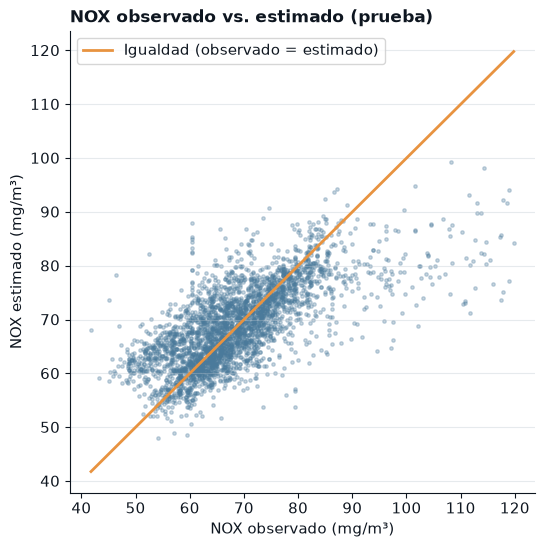

In [22]:
# Espacio de resolución — C8 · prueba final (sin reajustar ni cambiar el modelo)
X_prueba, y_prueba = prueba[PREDICTORES], prueba[OBJETIVO]

modelo_media = candidatos[0][2]   # media (referencia), ya ajustada en C6
# modelo_lineal y modelo_elegido (Ridge alpha = 1) vienen de C7, ya ajustados

# Como el candidato elegido es Ridge, se evalúan tres modelos: media, lineal y Ridge elegido
a_evaluar = [
    ("Media (referencia)", modelo_media),
    ("Lineal", modelo_lineal),
    (f"Candidato: {elegido['metodo']} (alpha={elegido['alpha']:g})", modelo_elegido),
]

filas, preds = [], {}
for nombre, modelo in a_evaluar:
    p = modelo.predict(X_prueba)
    preds[nombre] = p
    filas.append({"modelo": nombre, "RMSE_prueba": rmse(y_prueba, p),
                  "MAE_prueba": mean_absolute_error(y_prueba, p)})
tabla_c8 = pd.DataFrame(filas)
display(tabla_c8.round(6))

# Diferencia de RMSE del candidato respecto de lineal (con precisión suficiente)
nombre_cand = a_evaluar[2][0]
dif = tabla_c8.loc[2, "RMSE_prueba"] - tabla_c8.loc[1, "RMSE_prueba"]
print(f"Diferencia de RMSE (candidato - lineal) en prueba: {dif:.8f} mg/m³")
print(f"Diferencia de RMSE (candidato - lineal) en validación: "
      f"{elegido['RMSE_val'] - tabla_c6.loc[1, 'RMSE_val']:.8f} mg/m³")

# Gráfico: NOX observado vs. estimado por el candidato
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_prueba, preds[nombre_cand], s=6, alpha=0.3, color=AZUL)
lim = [min(y_prueba.min(), preds[nombre_cand].min()), max(y_prueba.max(), preds[nombre_cand].max())]
ax.plot(lim, lim, color=AMBAR, linewidth=2, label="Igualdad (observado = estimado)")
ax.set_title("NOX observado vs. estimado (prueba)")
ax.set_xlabel("NOX observado (mg/m³)")
ax.set_ylabel("NOX estimado (mg/m³)")
ax.legend()
plt.show()

**Interpretación.** En prueba, la media da un RMSE de 10,9577 mg/m³, la lineal 7,8820 y Ridge con alpha = 1 da 7,8827. Los dos modelos bajan el error cerca de un 28 % respecto de la media.

En validación Ridge le ganaba a la lineal por 0,0012 mg/m³, pero en prueba pierde por 0,0007 mg/m³. O sea que esa ventaja no se mantuvo. En MAE Ridge queda apenas mejor (5,5709 contra 5,5711).

Todas estas diferencias son de una milésima, y el error ronda los 7,9 mg/m³, así que no son importantes: lineal y Ridge rinden prácticamente igual. Una diferencia importante sería como la que hay entre los modelos y la media, de unos 3 mg/m³.

En el gráfico los puntos siguen la diagonal, pero con bastante dispersión. Los valores altos de `NOX` (más de 90 mg/m³) quedan subestimados.

## 8.3 Consigna C9 — Errores concretos y comparación por año

Identificar los dos mayores errores absolutos del candidato y mostrar ID, año, NOX observado, estimación y error con signo, definido como estimación menos observación. Comentar sobreestimación o subestimación y plantear una hipótesis prudente, sin alterar filas ni atribuir causas.

Calcular por año cantidad de casos y RMSE de lineal y candidato. Relacionar este diagnóstico con la tabla anual de C4 y explicar por qué no equivale a una evaluación en años futuros.

In [23]:
# Espacio de resolución — C9 · errores y años (prueba, sin cambiar el modelo)
res = prueba[["id_medicion", "anio"]].copy()
res["NOX_observado"] = y_prueba.values
res["NOX_estimado"] = preds[nombre_cand]
res["error_con_signo"] = res["NOX_estimado"] - res["NOX_observado"]   # estimación - observación
res["error_abs"] = res["error_con_signo"].abs()
res["pred_lineal"] = preds["Lineal"]

# 1) Los dos mayores errores absolutos del candidato
print("Dos mayores errores absolutos del candidato:")
display(res.nlargest(2, "error_abs")[
    ["id_medicion", "anio", "NOX_observado", "NOX_estimado", "error_con_signo"]].round(3))

# 2) Por año: casos y RMSE de lineal y candidato
por_anio = res.groupby("anio").apply(lambda g: pd.Series({
    "casos": len(g),
    "RMSE_lineal": rmse(g["NOX_observado"], g["pred_lineal"]),
    "RMSE_candidato": rmse(g["NOX_observado"], g["NOX_estimado"]),
}), include_groups=False)
por_anio["casos"] = por_anio["casos"].astype(int)
print("\nRMSE por año en prueba:")
display(por_anio.round(4))

Dos mayores errores absolutos del candidato:


,id_medicion,anio,NOX_observado,NOX_estimado,error_con_signo
937,2011_06194,2011,117.35,73.574,-43.776
990,2011_06474,2011,117.89,75.045,-42.845



RMSE por año en prueba:


,casos,RMSE_lineal,RMSE_candidato
anio,,,
2011,1133,7.4625,7.4616
2012,1150,7.3305,7.3327
2013,1046,8.8500,8.8508


**Interpretación.** Los dos mayores errores son los registros 2011_06194 y 2011_06474, los dos de 2011. En ambos el `NOX` real era muy alto (117,35 y 117,89 mg/m³) y el modelo estimó mucho menos (73,57 y 75,05). El error con signo es negativo (-43,78 y -42,85), o sea que el modelo subestimó. Puede ser que sean valores poco comunes, de la cola alta de `NOX`, que los nueve sensores no alcanzan a anticipar. No se tocó ninguna fila ni se afirma una causa.

Por año, lineal y candidato dan casi lo mismo: 2011: 7,4625 y 7,4616; 2012: 7,3305 y 7,3327; 2013: 8,8500 y 8,8508. El error es mayor en 2013, que en la tabla de C4 también tenía el mayor desvío de `NOX` (12,22), así que ese año hay más variabilidad difícil de estimar.

Esto no equivale a evaluar años futuros: los registros de prueba de cada año se mezclaron al azar con los de entrenamiento, así que el modelo ya vio datos de esos mismos años.

# 9. Responder y entregar una ejecución reproducible
## 9.1 Consigna C10 — Síntesis de 200–300 palabras

Responder por separado la parte de precisión y la de variación de coeficientes. Integrar un par correlacionado, dos cifras de comparación final, un resultado del diagnóstico de submuestras y un error o diferencia anual. Explicitar dos límites y una extensión futura que requiera nueva evaluación. No presentar magnitudes de coeficientes como causas ni afirmar que se replica el protocolo temporal de UCI.

Antes de entregar: reiniciar kernel, ejecutar de principio a fin, revisar salidas e interpretaciones, conservar rutas relativas y registrar las fuentes consultadas. No se pide otro informe.

**Respuesta.**

**Precisión.** Ridge no mejora la precisión de forma importante respecto de la regresión lineal. En validación, Ridge con alpha = 1 era un poco mejor (RMSE 7,7930 contra 7,7942 mg/m³), pero en prueba la lineal dio 7,8820 y Ridge 7,8827 mg/m³. La diferencia es de 0,0007 mg/m³, cambió de signo y es mínima frente a un error de casi 8 mg/m³. Los dos modelos mejoran mucho a la media (10,9577 mg/m³). Por año, el error es mayor en 2013 (RMSE 8,85) que en 2011 (7,46) y 2012 (7,33), igual para ambos modelos.

**Variación de coeficientes.** `GTEP` y `CDP` son sensores casi iguales entre sí (r = 0,994). Al repetir el ajuste en cinco submuestras, Ridge redujo poco la variación de sus coeficientes: en `CDP` el desvío bajó de 0,9014 a 0,8748 y en `GTEP` de 0,4659 a 0,4470 (entre 3 % y 4 %). Esto muestra cuánto cambian los coeficientes, no qué sensor causa más o menos emisiones.

**Límites y extensión.** Primero, la partición es aleatoria y mezcla períodos, así que la evaluación puede salir más favorable que en un uso real, y no replica el protocolo de UCI (2011–2013 para desarrollo y 2014–2015 para prueba). Segundo, los datos son de una sola planta y no tienen fecha por fila. Como extensión futura, se podría probar el modelo en 2014–2015, lo que requeriría una nueva evaluación.

## 9.2 Registrar entorno y archivos

La celda siguiente informa versiones y disponibilidad de archivos. Completar la entrega con las decisiones e interpretaciones verificadas.

In [ ]:
display(pd.Series({paquete:version(paquete) for paquete in ["numpy","pandas","matplotlib","scikit-learn"]},name="version").to_frame())
assert all((RUTA_DATOS/f"{n}.csv").is_file() for n in ["entrenamiento","validacion","prueba"])
print("Datos locales disponibles. Verificar también respuestas e interpretaciones.")

,version
numpy,2.5.3
pandas,3.0.6
matplotlib,3.11.2
scikit-learn,1.9.1


Datos locales disponibles. Verificar también respuestas e interpretaciones.


**Interpretación.** Las versiones permiten reconstruir el entorno. Una ejecución sin errores no reemplaza la resolución de las diez consignas.

# Referencias

- [Gas Turbine CO and NOx Emission Data Set](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set), UCI Machine Learning Repository (2019). DOI: [10.24432/C5WC95](https://doi.org/10.24432/C5WC95). Datos bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Consulta: 18/9/2026.
- Department of Energy. [How Gas Turbine Power Plants Work](https://www.energy.gov/hgeo/how-gas-turbine-power-plants-work). Base del esquema conceptual y lectura de contexto; consulta: 18/9/2026.
- Scikit-learn. Documentación de [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) y [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Consulta: 18/9/2026.

La cátedra seleccionó años, excluyó CO y agregó identificadores y particiones, sin alterar mediciones. La fuente no avala las conclusiones. Ver `fuentes_licencias.md` y `diccionario.md` para trazabilidad.